# Fourier contour electromagnetic validation · isolated-fin controls and rotating-stack transport

This notebook retains the original **single-contour** hard-mask RCWA/FDTD, field, complex-frequency, fabrication and rotation checks as *controls*. A new section validates the same optimized contour as a **fixed-total-height rotating multilayer**, using the exact saved transport metadata. A single isolated Jones matrix is **not** a certified local propagation generator. An RCWA-order-stable nonorthogonal response must have appreciable absolute anisotropy and splitting, not simply a large eigenvector overlap.

## 1. Configuration, checkpoint, and computational toggles

Place this notebook and its two validation helpers beside the existing `engine_ellipse_*`, `engine_contour_*`, `engine_rcwa`, `engine_transmission_ep`, `engine_validate`, `engine_fdtd`, and `twofin` modules. The loader reads the **actual saved raw optimizer coordinates** and configuration metadata rather than inventing a replacement contour.

Set `CHECKPOINT` explicitly to choose a candidate; otherwise the newest compatible checkpoint is found. Only optimizer `contour_*.npz` checkpoints with complete geometry metadata are accepted. Set `DEMO_UNOPTIMIZED=True` only for a non-candidate demonstration.

In [ ]:
# Shared engines live in ../core (see ../PROJECTS.md). Run with the notebook folder as cwd.
import sys; from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / 'core').resolve()))

In [20]:
from dataclasses import replace
from pathlib import Path
import importlib, json, time
from engine_contour_checkpoint import checkpoint_candidates, read_candidate, engine_stack
import numpy as np
import matplotlib.pyplot as plt
import torch

from twofin import Config
from engine_rcwa import Settings as RCWASettings
from engine_fdtd import Settings as FDTDSettings
from engine_validate import (fresnel, fresnel_yee, metrics, check, display_matrix,
    print_polarization_modes, plot_poincare, eigenstate_path,
    pancharatnam_phase, plot_path, change_reference_planes,
    scattering_comparison, quality_gates, yee_wavenumber)
from engine_transmission_ep import diagnostics as ep_diagnostics, screen_candidate, circular_blocks
from engine_contour_validation import (epsilon_map_contour, polygon_coverage, jones_metrics,
    four_blocks, power_budget, phase_report, runtime_checks, channel_phase)
from engine_contour_fdtd import solve as contour_fdtd_solve

MODEL = 'ellipse'                # 'ellipse', 'fourier', or None for auto-detect
CHECKPOINT = None                # e.g. 'results/elliptical_contour_transmission_ep/contour_XXXX.npz'
DEMO_UNOPTIMIZED = False         # Explicitly opt in to an unsaved geometry demo
ALLOW_ENGINE_MISMATCH = False   # Fail closed on changed geometry/RCWA modules
RUN_RCWA = True
RUN_RCWA_CONVERGENCE = True
RUN_FDTD = False                 # Eight expensive independent time-domain launches
CAPTURE_EFIELD = True           # Only used if RUN_FDTD=True
RUN_FDTD_CONVERGENCE = True    # dx=20 and 10 nm comparison; much more expensive
RUN_FABRICATION_SWEEP = True
RUN_COMPLEX_FREQUENCY = False # Costly independent resonance exploration; opt in
RUN_ROTATION_TRANSPORT = False # Single-layer control; full transport in multilayer notebook
RUN_EXPORT_GDS = False         # Optional gdstk dependency
FORCE_FDTD = False

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT = Path('results/fourier_contour_validation')
OUT.mkdir(parents=True,exist_ok=True)

# Shared engines and reference planes are selected from the saved checkpoint
# in the next cell; no ContourRules or RCWA defaults are used for validation.
if MODEL not in ('ellipse','fourier',None):
    raise ValueError("MODEL must be 'ellipse', 'fourier' or None")
if not (RUN_RCWA or RUN_FDTD) and not DEMO_UNOPTIMIZED:
    raise RuntimeError('Enable at least one forward solver for actual validation.')


In [21]:
# The optimizer checkpoint contains the complete physical/rules/solver manifest.
if CHECKPOINT is None:
    if MODEL is None:
        candidates = checkpoint_candidates('ellipse') + checkpoint_candidates('fourier')
        candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    else:
        candidates = checkpoint_candidates(MODEL)
    # For this experiment prefer the newly optimized physical stack.
    transport = [p for p in candidates if p.name.startswith('contour_transport_')]
    CHECKPOINT = (transport or candidates)[0] if candidates else None

if CHECKPOINT is None:
    if not DEMO_UNOPTIMIZED:
        raise FileNotFoundError('No optimized contour_*.npz found; set CHECKPOINT to a '
                                'checkpoint saved by the optimization notebook.')
    # A clearly labeled geometry-only demo; never treated as a trained candidate.
    chosen_kind = MODEL or 'ellipse'
    geom,rcwa_module,inverse=engine_stack(chosen_kind)
    from engine_rcwa import Settings as RCWASettings
    ContourRules, ContourDesign = geom.ContourRules, geom.ContourDesign
    cfg=Config(wavelength=.633,period=.400,n_sub=1.46,n_fin=2.584,n_fin_kappa=0.)
    rules=ContourRules(period=cfg.period)
    raw=np.asarray(ContourDesign(rules,device='cpu',dtype=torch.float64).export())
    checkpoint_meta={}
    FIXED_PORTS=tuple(rcwa_module.FIXED_PORTS)
    rc_settings=RCWASettings(order=5,raster=192,device=DEVICE,precision='complex128')
    convergence_orders=(5,7,9)
    convergence_raster=256
    print('WARNING: UNOPTIMIZED geometry demo, not an EP candidate.')
else:
    saved=read_candidate(CHECKPOINT,expected_kind=MODEL,
        allow_engine_mismatch=ALLOW_ENGINE_MISMATCH)
    geom,rcwa_module,inverse=saved['geom'],saved['solver'],saved['inverse']
    ContourRules,ContourDesign=geom.ContourRules,geom.ContourDesign
    cfg,rules,raw=saved['cfg'],saved['rules'],saved['raw']
    checkpoint_meta=saved['metadata']
    FIXED_PORTS=saved['fixed_ports']
    rc_settings=replace(saved['refine_settings'],device=DEVICE)
    convergence_orders=saved['verify_orders']
    convergence_raster=saved['verify_raster']
    print('Loaded exact optimizer checkpoint:',saved['path'])
    print('Saved geometry rules:',rules)
    print('Saved refinement settings:',rc_settings)
    if saved['engine_drift']:
        print('WARNING: engine signature differences:',saved['engine_drift'])

# Import the same geometry and optical forward solver the optimizer used.
MODEL='ellipse' if 'axis_ratio_bounds' in vars(rules) else 'fourier'
contour_points,contour_fill=geom.contour_points,geom.contour_fill
fabrication_cost,hard_mask_checks=geom.fabrication_cost,geom.hard_mask_checks
real_dtype=geom.real_dtype
solve_contour_torch=rcwa_module.solve_contour_torch
print('Model:',MODEL,'| geometry engine:',geom.__file__)
print('RCWA engine:',rcwa_module.__file__,'| device:',DEVICE)
print('Fixed monitor planes (µm):',FIXED_PORTS)

assert cfg.n_fin_kappa == 0 and np.isrealobj(cfg.n_fin)
assert abs(cfg.period-rules.period)<1e-12
if cfg.period>=cfg.wavelength/max(cfg.n_sub,1.):
    print('WARNING: substrate diffraction channels may be open; 4×4 S is incomplete')
rules.validate()

# Recover the physical height from the optimized unconstrained coordinates.
model=ContourDesign(rules,raw,device=DEVICE,dtype=torch.float64)
with torch.no_grad():
    parameters=model.values()
    points=contour_points(parameters,rules).detach().cpu().numpy()
    height=float(parameters['height'].detach().cpu())
    fab,terms=fabrication_cost(parameters,rules)
    nominal_raw=np.asarray(raw,float)

cfg=replace(cfg,height=height)
cfg.validate()
# Use the top reference plane stored by the optimizer checkpoint.
fd_port_top=float(FIXED_PORTS[1]-cfg.height)
fd_settings=FDTDSettings(dx_nm=20.,samples=5,backend=('torch.cuda.float32' if DEVICE=='cuda' else 'numpy'),
    port_bottom=float(FIXED_PORTS[0]),port_top_offset=fd_port_top,
    source_top_offset=fd_port_top+.32,top_um=fd_port_top+.72)
fd_settings.validate(cfg)
print('Physical height (µm):',cfg.height,'| n_fin:',cfg.n_fin)
print('FDTD:',fd_settings)
print('Fabrication proxies:',{k:round(float(v.detach().cpu()),5) for k,v in terms.items()})
print('Raw design dimensions:',len(nominal_raw))

Loaded exact optimizer checkpoint: results/elliptical_contour_transmission_ep/contour_transport_7de41184180b129f.npz
Saved geometry rules: ContourRules(period=0.4, harmonics=16, angular_samples=1024, cell_margin=0.02, perturbation_pad=0.008, min_neck_um=0.05, min_tip_radius_um=0.012, preferred_aspect=10.0, maximum_aspect=16.0, min_periodic_gap_um=0.04, edge_um=0.004, radius_bounds=[0.06, 0.17], height_bounds=[0.633, 0.633], harmonic_amplitude=1.8, axis_ratio_bounds=[1.0, 5.5])
Saved refinement settings: Settings(order=6, raster=224, samples=3, device='cuda', precision='complex128')
Model: ellipse | geometry engine: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/engine_ellipse_contour.py
RCWA engine: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/engine_ellipse_rcwa.py | device: cuda
Fixed monitor planes (µm): (-0.52, 1.05)
Physical height (µm): 0.633 | n_fin: 2.584
FDTD: Settings(dx_nm=20.0, samples=5, pml_um=0.3, bottom_um=1.2, t

## 2. Continuous polygon, binary mask, and independent FDTD raster

The optimizer's **hard analytical mask**, the explicitly sampled contour polygon, and the subpixel FDTD raster are plotted together. They should describe the same TiO₂ region. The independent polygon rasterization here does not reuse the optimizer's soft boundary function; disagreement indicates a geometry export or sampling problem.

The dielectric is patterned only between $z=0$ and $z=h$; the lower half-space is SiO₂. No additional fins, cavities, or layers are introduced.

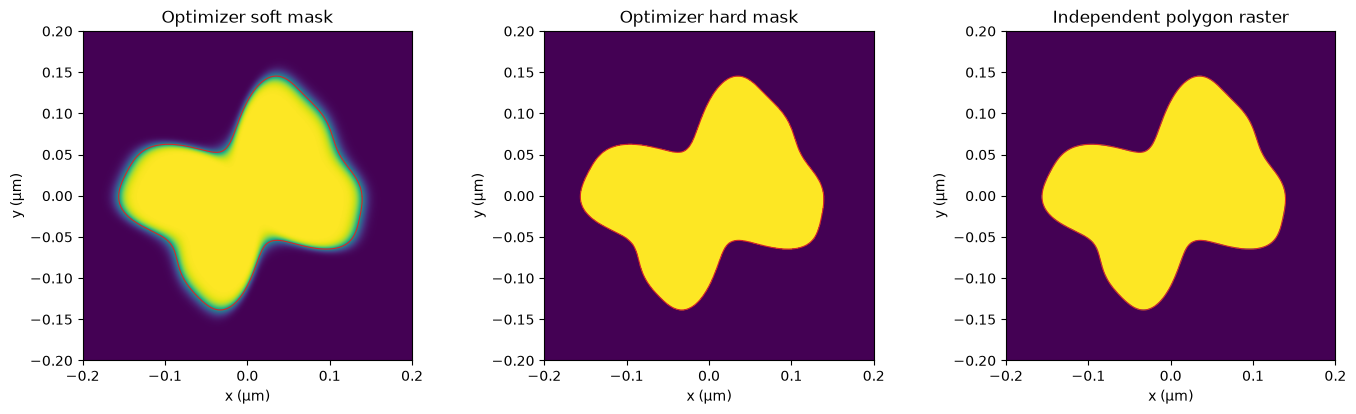

Hard-mask vs polygon-raster mean absolute difference: 0.0013298610833939164
FDTD epsilon map: (20, 20, 179) | memory (MiB): 0.3
FDTD n(x,y) fill fraction: 0.0 1.0
Hard fabrication morphology: {'opening_area_loss': 0.00165460642428521, 'components': 1, 'min_border_gap_um': np.float64(0.088), 'mask_area_um2': 0.045328}


In [22]:
with torch.no_grad():
    hard=contour_fill(parameters,rules,400,hard=True).detach().cpu().numpy()
    soft=contour_fill(parameters,rules,400).detach().cpu().numpy()
poly=polygon_coverage(points,cfg.period,400,samples=3)
eps,spec=epsilon_map_contour(cfg,points,dx_nm=fd_settings.dx_nm,
    samples=fd_settings.samples,bottom_um=fd_settings.bottom_um,
    top_um=fd_settings.top_um,pml_um=fd_settings.pml_um)
h=cfg.period/2
fig,axs=plt.subplots(1,3,figsize=(14,4.2))
for ax,img,title in zip(axs,(soft,hard,poly),('Optimizer soft mask','Optimizer hard mask','Independent polygon raster')):
    ax.imshow(img.T,origin='lower',extent=(-h,h,-h,h),vmin=0,vmax=1)
    ax.plot(*points.T,lw=.8,color='tab:red')
    ax.set(title=title,xlabel='x (µm)',ylabel='y (µm)',aspect='equal')
fig.tight_layout();plt.show()
print('Hard-mask vs polygon-raster mean absolute difference:',np.mean(abs(hard-poly)))
print('FDTD epsilon map:',eps.shape,'| memory (MiB):',round(eps.nbytes/2**20,1))
print('FDTD n(x,y) fill fraction:',float(spec['fill'].min()),float(spec['fill'].max()))
print('Hard fabrication morphology:',hard_mask_checks(hard,rules))

## 3. Bare silica–air Fresnel reference

The bare interface is a known analytical reference at $z=0$. Its complex reflection and transmission amplitudes include free-space/substrate travel to the fixed monitor planes. The FDTD-grid dispersion prediction is printed separately and **never fitted** to numerical data.

In [23]:
ports=tuple(float(z) for z in FIXED_PORTS)
S_analytic=fresnel(cfg,*ports)
S_yee=fresnel_yee(cfg,*ports,fd_settings.dx_nm/1000)
display_matrix(S_analytic,'Analytic bare-interface S')
print('Bare-interface conservation:',metrics(S_analytic))
print('Expected Yee-vs-continuum complex difference:',np.max(abs(S_yee-S_analytic)))
for n,label in [(cfg.n_sub,'silica'),(1.,'air')]:
    k_exact=2*np.pi*n/cfg.wavelength
    k_yee=yee_wavenumber(cfg,fd_settings.dx_nm/1000,n)
    print(label,'continuous k:',k_exact,'Yee k:',k_yee,'difference:',k_yee-k_exact)

Analytic bare-interface S: bottom(x,y), top(x,y)

-0.15040+0.11111j  -0.00000+0.00000j  +0.61727-0.76420j  +0.00000+0.00000j
-0.00000+0.00000j  -0.15040+0.11111j  +0.00000+0.00000j  +0.61727-0.76420j
+0.61727-0.76420j  +0.00000+0.00000j  +0.07699-0.17041j  +0.00000+0.00000j
+0.00000+0.00000j  +0.61727-0.76420j  +0.00000+0.00000j  +0.07699-0.17041j

Magnitude:
[[0.18699 0.      0.98236 0.     ]
 [0.      0.18699 0.      0.98236]
 [0.98236 0.      0.18699 0.     ]
 [0.      0.98236 0.      0.18699]]
Phase (deg):
[[143.55 180.   -51.07   0.  ]
 [180.   143.55   0.   -51.07]
 [-51.07   0.   -65.69   0.  ]
 [  0.   -51.07   0.   -65.69]]
Bare-interface conservation: {'reciprocity_max': 0.0, 'unitarity_max': 6.206335383118183e-17, 'passivity_lambda_max': 1.0, 'worst_power_error': 0.0}
Expected Yee-vs-continuum complex difference: 0.033514371897553547
silica continuous k: 14.492022983384196 Yee k: 14.535378816359273 difference: 0.04335583297507739
air continuous k: 9.926043139304243 Yee k: 9.

## 4. Hard-boundary RCWA scattering and independent bare-interface RCWA

This is **forward-only**, with no soft geometry or optimizer gradients. Use a fully binary contour mask, then evaluate the normalized zeroth-order complex S. The bare interface is calculated using the independent numerical RCWA baseline supplied by the validation helper. All reference planes coincide with those used during optimization.

In [24]:
from engine_contour_validation import bare_rcwa
rc=None
rc_bare=None
if RUN_RCWA:
    start=time.perf_counter()
    with torch.no_grad():
        p=ContourDesign(rules,raw,device=DEVICE,dtype=real_dtype(rc_settings)).values()
        S_rcwa=solve_contour_torch(cfg,rc_settings,p,rules,hard=True,
                  ports=ports).detach().cpu().numpy()
    rc=dict(S=S_rcwa,elapsed_s=time.perf_counter()-start)
    rc_bare=bare_rcwa(cfg,rc_settings,ports)
    scattering_comparison(rc_bare,S_analytic,'RCWA bare / analytical Fresnel')
    display_matrix(rc['S'],'Hard-contour RCWA scattering S')
    check(rc['S'])
    print('RCWA time (s):',rc['elapsed_s'])

RCWA bare / analytical Fresnel: max |ΔS|=0.000000, max ||S|-|Sref||=0.000000, max |Δphase| (|Sref|>0.05)=0.000°
Hard-contour RCWA scattering S: bottom(x,y), top(x,y)

+0.12868+0.23418j  -0.01806+0.11323j  +0.03867-0.91534j  +0.26839-0.06385j
-0.01806+0.11323j  +0.16941+0.05468j  +0.27251-0.04473j  -0.48453-0.80257j
+0.03867-0.91534j  +0.27251-0.04473j  +0.18639-0.21340j  +0.05477-0.03341j
+0.26839-0.06385j  -0.48453-0.80257j  +0.05477-0.03341j  +0.06569-0.19120j

Magnitude:
[[0.26721 0.11466 0.91616 0.27588]
 [0.11466 0.17802 0.27616 0.9375 ]
 [0.91616 0.27616 0.28333 0.06415]
 [0.27588 0.9375  0.06415 0.20217]]
Phase (deg):
[[  61.21   99.06  -87.58  -13.38]
 [  99.06   17.89   -9.32 -121.12]
 [ -87.58   -9.32  -48.86  -31.39]
 [ -13.38 -121.12  -31.39  -71.04]]
reciprocity_max            : 6.51668e-14
unitarity_max              : 4.87924e-14
passivity_lambda_max       : 1
worst_power_error          : 2.35367e-14
RCWA time (s): 0.8331728838384151


## 5. Optional independent FDTD + Yee-dispersion calibration

This uses flaport/fdtd, **not** the two-fin geometry map. Eight independent soft-plane runs assemble the four-channel S: four with the contour, four for the bare interface. The x/y boundaries are periodic, and the z ends use PML. Time-domain plane-wave extraction and homogeneous Yee-phase corrections match the attached `TwoFin_Engine.ipynb` method.

The scalar volume-fraction grid approximates material interfaces and should not be treated as exact. The FDTD run can be substantially more expensive; `RUN_FDTD=False` by default.

In [25]:
fd=None
fd_ports=ports
if RUN_FDTD:
    fd=contour_fdtd_solve(cfg,fd_settings,points,cache=OUT,force=FORCE_FDTD,
                          snapshot=CAPTURE_EFIELD)
    fd_ports=tuple(float(z) for z in fd['ports'])
    scattering_comparison(fd['S_flat'],fresnel(cfg,*fd_ports),
                          'Raw FDTD bare vs continuum Fresnel')
    scattering_comparison(fd['S_flat'],fd['S_fresnel_yee'],
                          'Raw FDTD bare vs Yee Fresnel')
    scattering_comparison(fd['S_flat_phase_aligned'],fresnel(cfg,*fd_ports),
                          'Phase-corrected FDTD bare vs Fresnel')
    display_matrix(fd['S_phase_aligned'],'Contour FDTD S (corrected Yee propagation)')
    check(fd['S_phase_aligned'])
    print('FDTD acquisition residual maximum:',max(fd['acquisition_residuals']))
    print('FDTD simulation seconds:',sum(fd['durations_s']))
    print('Peak CUDA allocation MiB:',np.nanmax(fd['cuda_peak_mb']) if DEVICE=='cuda' else 'CPU backend')
    # The intended planes are fixed; FDTD cell-center snapping can shift them.
    from engine_validate import change_reference_planes
    fd_S_monitor=change_reference_planes(fd['S_phase_aligned'],cfg,fd_ports,ports)
    fd_flat_monitor=change_reference_planes(fd['S_flat_phase_aligned'],cfg,fd_ports,ports)
    quality_gates(fd_S_monitor,flat=fd_flat_monitor,analytic=S_analytic,
                  other=(rc['S'] if rc else None),acq=fd['acquisition_residuals'])

### 5a. Paired instantaneous electric-field cross sections

Under the **same bottom-incident x-polarized excitation**, compare a bare interface and the contour geometry. Snapshots display $E_x(x,z,t_\mathrm{final})$, not intensity or $|E|$, with a common scale. Gray bands mark z-PML. They are only meaningful when actually recorded by the FDTD run.

In [26]:
if fd is not None and CAPTURE_EFIELD:
    flat=np.asarray(fd['snapshot_flat_xz']); contour=np.asarray(fd['snapshot_contour_xz'])
    x,z=spec['x'],spec['z']
    assert flat.shape==contour.shape==(len(x),len(z)), (flat.shape,contour.shape,eps.shape)
    vmax=max(np.max(abs(flat)),np.max(abs(contour)),1e-12)
    fig,axs=plt.subplots(1,2,figsize=(13,4),sharex=True,sharey=True)
    for ax,E,label in zip(axs,(flat,contour),('Bare interface','Fourier contour')):
        im=ax.imshow(E.T,origin='lower',aspect='auto',cmap='RdBu_r',vmin=-vmax,vmax=vmax,
                     extent=(x[0],x[-1],z[0],z[-1]))
        ax.axhspan(z[0],z[spec['npml']],color='gray',alpha=.2)
        ax.axhspan(z[-spec['npml']],z[-1],color='gray',alpha=.2)
        ax.axhline(0,color='black',lw=.7)
        ax.axhline(cfg.height,color='black',ls='--',lw=.7)
        ax.set(title=label,xlabel='x (µm)',ylabel='z (µm)')
    fig.colorbar(im,ax=axs,label='Instantaneous Ex (simulation units)')
    plt.show()
else:
    print('FDTD field captures disabled; no field arrays fabricated from S matrices.')

FDTD field captures disabled; no field arrays fabricated from S matrices.


## 6. RCWA ↔ FDTD complex S comparison (when available)

Compare uncorrected matrices to identify numerical propagation differences, then compare FDTD with its **predicted** homogeneous Yee-phase correction. Phase comparisons mask near-zero reference amplitudes. Never align phases by arbitrary fitted constants.

In [27]:
if fd is not None and rc is not None:
    fd_raw_at_ports=change_reference_planes(fd['S'],cfg,fd_ports,ports)
    scattering_comparison(fd_raw_at_ports,rc['S'],'Raw FDTD / RCWA')
    scattering_comparison(fd_S_monitor,rc['S'],'Yee-corrected FDTD / RCWA')
    ds=fd_S_monitor-rc['S']
    phase=np.rad2deg(np.angle(fd_S_monitor*np.conj(rc['S'])))
    phase=np.ma.masked_where(abs(rc['S'])<.05,phase)
    fig,axs=plt.subplots(1,2,figsize=(10,4))
    im0=axs[0].imshow(abs(ds),cmap='magma');axs[0].set(title='|ΔS|',xlabel='Input',ylabel='Output')
    im1=axs[1].imshow(phase,cmap='twilight',vmin=-180,vmax=180)
    axs[1].set(title='Elementwise phase residual (deg)',xlabel='Input',ylabel='Output')
    fig.colorbar(im0,ax=axs[0]);fig.colorbar(im1,ax=axs[1]);plt.show()
else:
    print('Both RUN_FDTD and RUN_RCWA are needed for independent solver agreement.')

Both RUN_FDTD and RUN_RCWA are needed for independent solver agreement.


## 7. Full complex scattering matrix — phase and power retained

Use the **hard-mask highest-order RCWA result** as the characterization default; use phase-corrected FDTD only if RCWA is disabled. The scattering matrix remains power normalized, with the physical common Jones phase at fixed monitor planes. We do **not** divide entries by arbitrary channel phases.

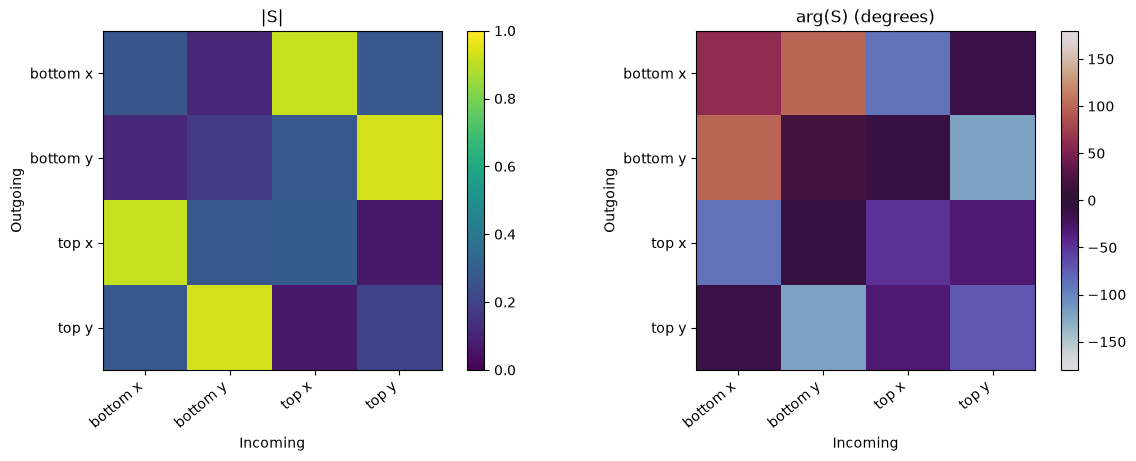

Scattering quality: {'reciprocity_max': 6.516682888338742e-14, 'unitarity_max': 4.87924376166521e-14, 'passivity_lambda_max': 1.0000000000000735, 'worst_power_error': 2.353672812205332e-14}


In [28]:
S_char=np.asarray(rc['S'] if rc is not None else
                  fd_S_monitor if fd is not None else S_analytic,complex)
S_base=np.asarray(rc_bare if rc_bare is not None else
                  fd_flat_monitor if fd is not None else S_analytic,complex)
labels=['bottom x','bottom y','top x','top y']
mag=abs(S_char)
threshold=max(1e-5,.01*mag.max())
phase=np.ma.masked_where(mag<threshold,np.angle(S_char,deg=True))
fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
i0=axs[0].imshow(mag,vmin=0,vmax=1)
i1=axs[1].imshow(phase,vmin=-180,vmax=180,cmap='twilight')
for ax,t in zip(axs,('|S|','arg(S) (degrees)')):
    ax.set(title=t,xticks=range(4),yticks=range(4),xlabel='Incoming',ylabel='Outgoing')
    ax.set_xticklabels(labels,rotation=40,ha='right');ax.set_yticklabels(labels)
fig.colorbar(i0,ax=axs[0]);fig.colorbar(i1,ax=axs[1]);plt.show()
print('Scattering quality:',metrics(S_char))

### 7a. Reflection and transmission power budget

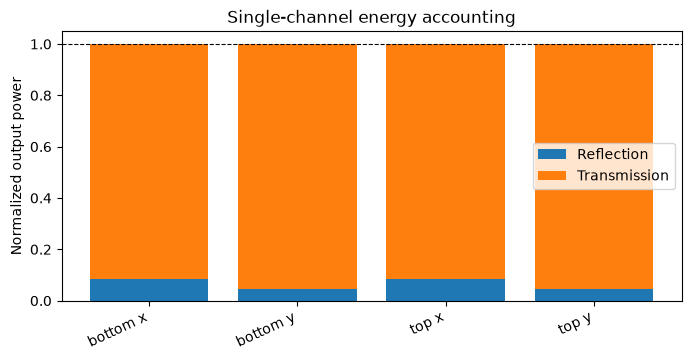

bottom x: R=0.08455, T=0.91545, 1-R-T=-1.132e-14
bottom y: R=0.04484, T=0.95516, 1-R-T=-1.343e-14
top x: R=0.08439, T=0.91561, 1-R-T=-2.554e-15
top y: R=0.04499, T=0.95501, 1-R-T=-2.354e-14


In [29]:
R,T=power_budget(S_char)
fig,ax=plt.subplots(figsize=(8,3.5))
ax.bar(labels,R,label='Reflection');ax.bar(labels,T,bottom=R,label='Transmission')
ax.axhline(1,color='black',lw=.8,ls='--')
ax.set(ylabel='Normalized output power',title='Single-channel energy accounting')
ax.legend();plt.xticks(rotation=25,ha='right');plt.show()
for label,r,t in zip(labels,R,T):
    print(f'{label}: R={r:.5f}, T={t:.5f}, 1-R-T={1-r-t:+.3e}')

### 7b. Jones phases and physical reference-plane choices

For nonsingular $J$, the phase $\tfrac12\arg\det J$ is defined only **modulo $\pi$**. Coherent input/analyzer amplitudes $v^\dagger Ju$ retain their full $2\pi$ phase. Reference-plane conversion below moves the *same solved S* to device-face coordinates $(0,h)$; it does not remove internal physical phase or require a second solve.

In [30]:
for name,J in four_blocks(S_char).items():
    phase_report(J,name+' (monitor)')
S_faces=change_reference_planes(S_char,cfg,ports,(0.,cfg.height))
S_bare_faces=change_reference_planes(S_base,cfg,ports,(0.,cfg.height))
print('Monitor z:',ports,'Device faces:',(0.,cfg.height))
for label,S_here,S_ref in [('monitor',S_char,S_base),('faces',S_faces,S_bare_faces)]:
    print('\nAt',label,'planes:')
    for polarization,j in [('x',0),('y',1)]:
        measured=S_here[2+j,j]; bare=S_ref[2+j,j]
        print(polarization,'absolute transmitted phase:',channel_phase(measured),
              'phase relative to bare:',channel_phase(measured*np.conj(bare)))

R11 (monitor): det half-phase=+33.54° (mod 180°); trace phase=+44.10°; singular values=[0.31384 0.17575]
      x: |v†Jv|=0.26721, phase=+61.21°
      y: |v†Jv|=0.17802, phase=+17.89°
   +45°: |v†Jv|=0.28904, phase=+63.05°
      R: |v†Jv|=0.20755, phase=+44.10°
T21 (monitor): det half-phase=+75.89° (mod 180°); trace phase=-104.55°; singular values=[0.98444 0.94948]
      x: |v†Jv|=0.91616, phase=-87.58°
      y: |v†Jv|=0.93750, phase=-121.12°
   +45°: |v†Jv|=0.91448, phase=-87.02°
      R: |v†Jv|=0.88788, phase=-105.18°
T12 (monitor): det half-phase=+75.89° (mod 180°); trace phase=-104.55°; singular values=[0.98444 0.94948]
      x: |v†Jv|=0.91616, phase=-87.58°
      y: |v†Jv|=0.93750, phase=-121.12°
   +45°: |v†Jv|=0.91448, phase=-87.02°
      R: |v†Jv|=0.88706, phase=-103.92°
R22 (monitor): det half-phase=-61.75° (mod 180°); trace phase=-58.08°; singular values=[0.31384 0.17575]
      x: |v†Jv|=0.28333, phase=-48.86°
      y: |v†Jv|=0.20217, phase=-71.04°
   +45°: |v†Jv|=0.29707, pha

### 7c. Save complete complex response

The exported NPZ contains the **unchanged** complex S on monitor planes, the re-referenced complex S on device faces, numerical/analytic baseline, physical contour polygon, and optimizer coordinates.

In [31]:
characterization_file=OUT/'fourier_contour_scattering.npz'
np.savez_compressed(characterization_file,
    checkpoint=str(CHECKPOINT),
    optimizer_metadata=json.dumps(checkpoint_meta,sort_keys=True),S_monitor=S_char,S_device_faces=S_faces,
    S_flat_monitor=S_base,S_flat_device_faces=S_bare_faces,
    T21_monitor=S_char[2:,:2],T12_monitor=S_char[:2,2:],
    monitor_z_um=np.asarray(ports),face_z_um=np.array([0.,cfg.height]),
    contour_xy_um=points,raw_params=nominal_raw,hard_mask=hard,
    wavelength_um=cfg.wavelength,channel_labels=np.asarray(labels),model=MODEL)
print('Saved',characterization_file.resolve())

Saved /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/results/fourier_contour_validation/fourier_contour_scattering.npz


## 8 · Eigenpolarizations and non-normality of the **isolated fin** (control only)

The single-fin response is deliberately retained for comparison. The physically optimized object is the *full rotating stack* if the loaded checkpoint contains `metadata['transport']`. Transmission Jones eigenvectors need not equal local propagation-mode eigenvectors; this test alone does not establish complex geometric phase.


 R₁₁
  eigenstate 1: λ=+0.122227+0.288842j, |λ|=0.31364, phase=+67.06°, Stokes=[ 1.       0.62548  0.77959 -0.03174]
  eigenstate 2: λ=+0.175861+0.000024j, |λ|=0.17586, phase=+0.01°, Stokes=[ 1.      -0.62548 -0.77959 -0.03174]

 T₂₁
  eigenstate 1: λ=-0.599316-0.780708j, |λ|=0.98422, phase=-127.51°, Stokes=[ 1.      -0.6958  -0.71749  0.03252]
  eigenstate 2: λ=+0.153448-0.937207j, |λ|=0.94969, phase=-80.70°, Stokes=[ 1.       0.69632  0.7175  -0.01835]

 T₁₂
  eigenstate 1: λ=-0.599316-0.780708j, |λ|=0.98422, phase=-127.51°, Stokes=[ 1.      -0.69632 -0.7175  -0.01835]
  eigenstate 2: λ=+0.153448-0.937207j, |λ|=0.94969, phase=-80.70°, Stokes=[1.      0.6958  0.71749 0.03252]

 R₂₂
  eigenstate 1: λ=+0.205920-0.233590j, |λ|=0.31140, phase=-48.60°, Stokes=[ 1.       0.67818  0.71126 -0.18487]
  eigenstate 2: λ=+0.046154-0.171009j, |λ|=0.17713, phase=-74.90°, Stokes=[ 1.      -0.67818 -0.71126 -0.18487]


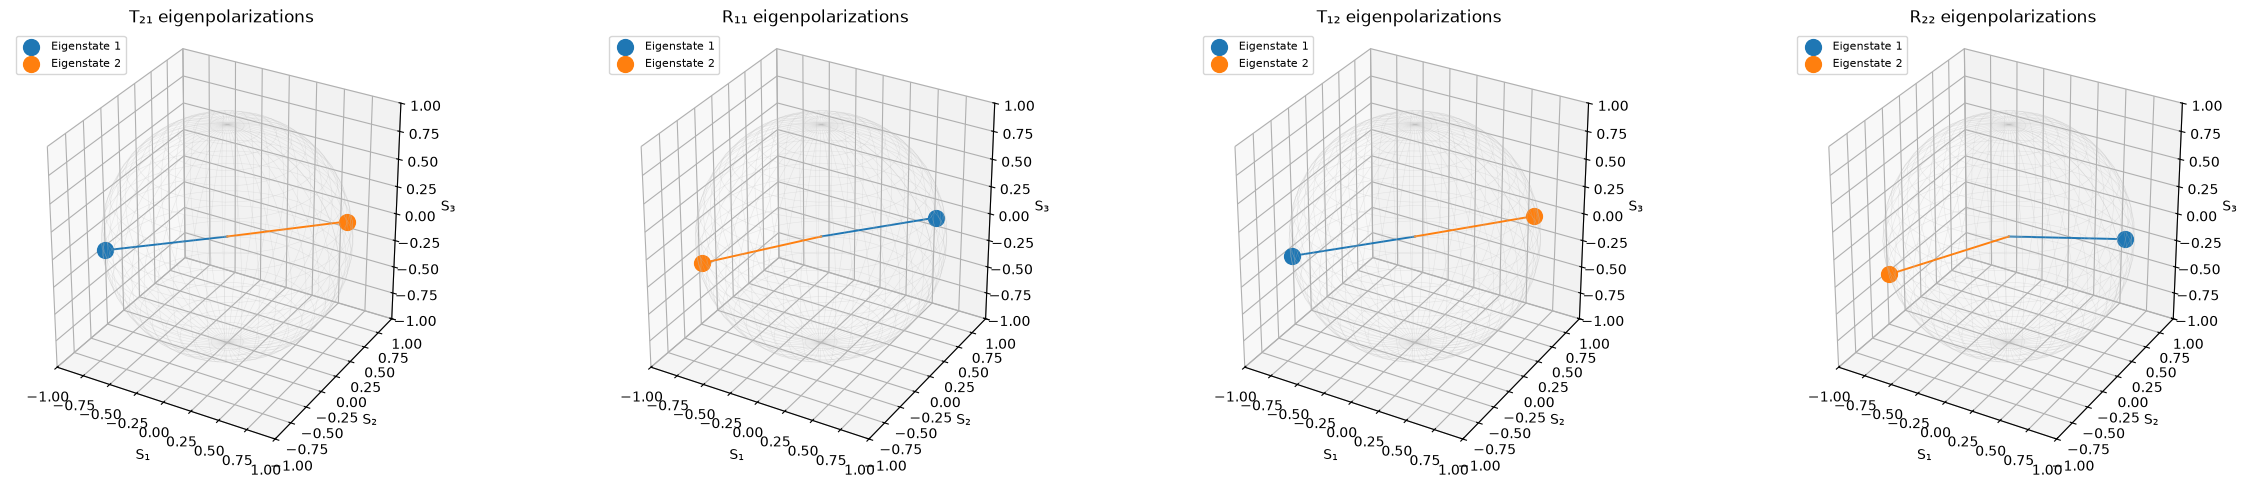

R11: gap=8.167e-01, overlap=0.031737, Jordan=0.5781, nonnormality=0.0300, non-scalar=0.5781, T/Ravg=0.0647
T21: gap=5.622e-01, overlap=0.007090, Jordan=0.3975, nonnormality=0.0032, non-scalar=0.3975, T/Ravg=0.9353
T12: gap=5.622e-01, overlap=0.007090, Jordan=0.3975, nonnormality=0.0032, non-scalar=0.3975, T/Ravg=0.9353
R22: gap=4.770e-01, overlap=0.184871, Jordan=0.3490, nonnormality=0.0616, non-scalar=0.3490, T/Ravg=0.0647
Transmission near-EP screen (numerical only): (False, ['T21: eigenvalue gap too large', 'T21: eigenvectors not coalesced', 'T21: not near rank-one', 'T12: eigenvalue gap too large', 'T12: eigenvectors not coalesced', 'T12: not near rank-one'])


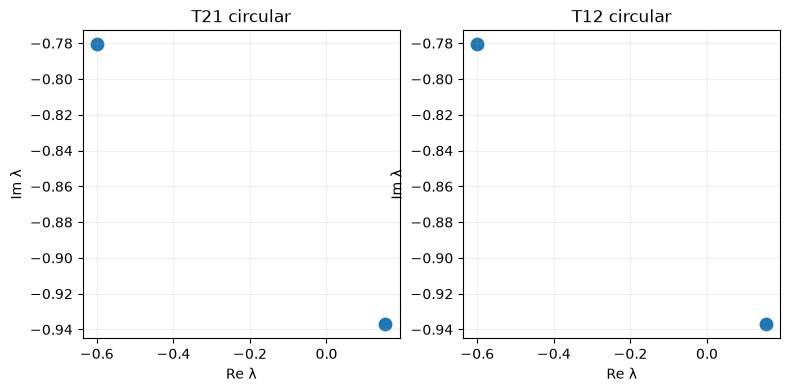

In [32]:
print_polarization_modes(S_char)
fig=plot_poincare(S_char,blocks=('T₂₁','R₁₁','T₁₂','R₂₂'))
plt.show()
for name,J in four_blocks(S_char).items():
    jm=jones_metrics(J)
    print(f'{name}: gap={jm["gap"]:.3e}, overlap={jm["overlap"]:.6f}, '
          f'Jordan={jm["jordan_strength"]:.4f}, '
          f'nonnormality={jm["nonnormality"]:.4f}, '
          f'non-scalar={jm["anisotropy"]:.4f}, T/Ravg={jm["mean_power"]:.4f}')
D=ep_diagnostics(S_char)
print('Transmission near-EP screen (numerical only):',screen_candidate(D))
Tc21,Tc12=circular_blocks(S_char)
fig,axs=plt.subplots(1,2,figsize=(9,4))
for ax,J,label in zip(axs,(Tc21,Tc12),('T21 circular','T12 circular')):
    eig=np.linalg.eigvals(J)
    ax.scatter(eig.real,eig.imag,s=80)
    ax.set(xlabel='Re λ',ylabel='Im λ',title=label);ax.grid(alpha=.2)
plt.show()

## 9 · RCWA convergence: isolate numerical near-scalar artifacts

For any transmission Jones matrix, report both the normalized eigenvalue separation and non-scalar strength. A nearly scalar Jones matrix can have an apparently large eigenvector overlap that shifts wildly with Fourier order even if total transmission power is stable. Converge both the full complex matrix and these polarization metrics.

order 6 complex ΔS nan T21 gap 0.5626856835774579 overlap 0.007187266622652367 unitarity 3.9079850467407096e-14
order 8 complex ΔS 0.03199383884464169 T21 gap 0.5565471261637379 overlap 0.00947055163308233 unitarity 9.912615319556509e-14
order 10 complex ΔS 0.018185020977979693 T21 gap 0.5539580656311689 overlap 0.01106051243634904 unitarity 4.664109404569193e-13
Highest-order complex deviation from initial: 0.04854058637844294


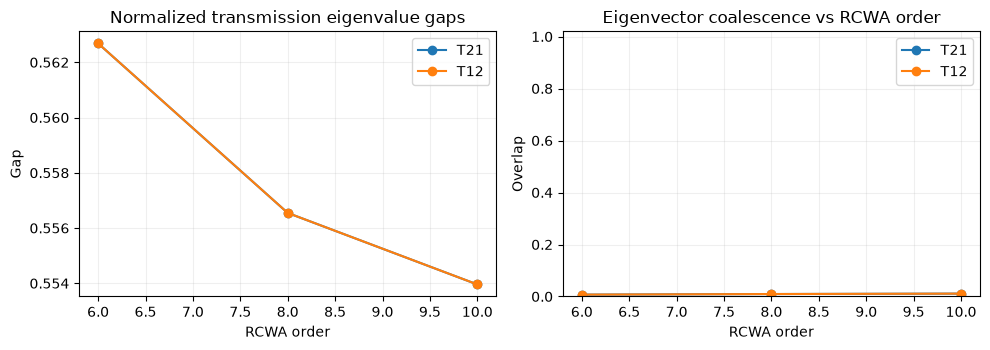

In [33]:
rc_series=[]
if RUN_RCWA and RUN_RCWA_CONVERGENCE:
    previous=None
    for order in convergence_orders:
        setting=replace(rc_settings,order=order,raster=convergence_raster)
        with torch.no_grad():
            prm=ContourDesign(rules,raw,device=DEVICE,dtype=real_dtype(setting)).values()
            curr=solve_contour_torch(cfg,setting,prm,rules,hard=True,
                     ports=ports).detach().cpu().numpy()
        d=ep_diagnostics(curr)
        m=metrics(curr)
        delta=np.nan if previous is None else float(np.max(abs(curr-previous)))
        row=dict(order=order,S=curr,delta_complex=delta,
                 T21_gap=d['T21']['gap'],T21_overlap=d['T21']['overlap'],
                 T12_gap=d['T12']['gap'],T12_overlap=d['T12']['overlap'],
                 T21_nonnormality=jones_metrics(curr[2:,:2])['nonnormality'],
                 unitarity=m['unitarity_max'],reciprocity=m['reciprocity_max'])
        rc_series.append(row)
        print('order',order,'complex ΔS',delta,'T21 gap',row['T21_gap'],
              'overlap',row['T21_overlap'],'unitarity',row['unitarity'])
        previous=curr
    # Promote the high-order matrix for downstream interpretation.
    S_converged=rc_series[-1]['S']
    print('Highest-order complex deviation from initial:',np.max(abs(S_converged-S_char)))
    fig,axs=plt.subplots(1,2,figsize=(10,3.6))
    axs[0].plot([v['order'] for v in rc_series],[v['T21_gap'] for v in rc_series],'o-',label='T21')
    axs[0].plot([v['order'] for v in rc_series],[v['T12_gap'] for v in rc_series],'o-',label='T12')
    axs[0].set(title='Normalized transmission eigenvalue gaps',xlabel='RCWA order',ylabel='Gap')
    axs[1].plot([v['order'] for v in rc_series],[v['T21_overlap'] for v in rc_series],'o-',label='T21')
    axs[1].plot([v['order'] for v in rc_series],[v['T12_overlap'] for v in rc_series],'o-',label='T12')
    axs[1].set(title='Eigenvector coalescence vs RCWA order',xlabel='RCWA order',ylabel='Overlap',ylim=(0,1.02))
    for ax in axs:ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();plt.show()
else:
    print('RCWA convergence disabled.')

### 9a. Optional FDTD spatial resolution convergence

Compare dx = 20 nm and dx = 10 nm only if `RUN_FDTD_CONVERGENCE=True`. Both matrices are re-referenced to the **same fixed physical ports**, correcting only the analytically predicted Yee homogeneous-region phase.

In [34]:
if RUN_FDTD and RUN_FDTD_CONVERGENCE:
    fd10=contour_fdtd_solve(cfg,replace(fd_settings,dx_nm=10.,samples=3),points,
                            cache=OUT,force=False,snapshot=False)
    f10=change_reference_planes(fd10['S_phase_aligned'],cfg,fd10['ports'],ports)
    print('FDTD dx=20→10 nm, maximum complex S change:',
          np.max(abs(f10-fd_S_monitor)))
else:
    print('FDTD resolution sweep disabled.')

FDTD resolution sweep disabled.


## 10. Complex-frequency pole–zero transmission maps

We evaluate the **same optimized, hard-edged periodic contour** using TORCWA at complex frequency. The time convention is $e^{-i\omega t}$: passive resonant poles should lie below the real axis ($\operatorname{Im}\omega<0$). Complex-frequency illumination is an **analytic continuation**, not a physically realizable indefinitely growing source; upper-half-plane samples are allowed as a mathematical probe.

The plotted observable is a **fixed Jones transmission amplitude**, $t_{ab}(f)=\langle a|T_{21}(f)|b\rangle$, with $a,b\in\{R,L\}$. Unlike an individual Jones eigenvalue, it is single-valued away from singularities, so poles and zeros can be examined without eigenvalue-branch exchanges. Change `COMPLEX_CHANNEL` to `LR`, `RL`, or `LL` as needed; the default `RR` does not guarantee two visible poles or zeros. A separate `det` option maps $\det T_{21}$.

The two heatmaps contain **direct complex-frequency RCWA samples**, not fabricated poles or a plotted fit. To help locate poles and zeros, we optionally fit an exploratory 2-zero/2-pole rational function and overlay candidates **only if the fit residual is sufficiently small**; that fit alone is not proof of two resonances. A full pole identification also requires local root refinement, convergence with RCWA order, and careful tracking of diffraction-order branches. The material is modeled as **dispersionless real-index TiO₂** in this experiment; causal dispersive $\varepsilon(\omega)$ would be required for quantitative material-pole predictions.

`COMPLEX_REAL_POINTS × COMPLEX_IMAG_POINTS` specifies the **actual number of expensive RCWA solves**. The default 101 × 101 scan is high resolution, but may be substantially more expensive than the optimization; try 25 × 25 first and increase only after checking branch smoothness. Interrupted scans resume automatically from their `.npz` cache. The normal-incidence real-axis transmission normalization is continued analytically as a fixed factor $\sqrt{n_{\mathrm{air}}/n_{\mathrm{sub}}}$; no real-flux normalization is applied off the real axis. The real-frequency consistency check uses the exact monitor planes recovered from the optimizer checkpoint; the maps use the native device-face coefficients (z=0 and z=height), which remove trivial homogeneous propagation phase without arbitrary offsets.


In [35]:
from engine_contour_complex_frequency import (
    prepare_epsilon, complex_transmission, frequency_grid, cache_identity,
    sweep_grid, rational22, projected_channel, plot_complex_maps, C_THZ_UM
)

# Frequency f = 1/lambda in the TORCWA unit system (cycles / micrometre).
# Ranges below are relative to f0=1/cfg.wavelength.
COMPLEX_CHANNEL = 'RR'             # RR, RL, LR, LL, xx, xy, ... or det
COMPLEX_REAL_RANGE = (0.85, 1.15)
COMPLEX_IMAG_RANGE = (-0.12, 0.02)
COMPLEX_REAL_POINTS = 50          # Direct RCWA samples (not interpolation)
COMPLEX_IMAG_POINTS = 50
COMPLEX_ORDER = 6                  # Increase to verify candidate poles/zeros
COMPLEX_RASTER = 192
COMPLEX_AMPLITUDE_SCALE = 'log10'  # 'log10' or 'linear'

if RUN_COMPLEX_FREQUENCY:
    complex_settings = RCWASettings(
        order=COMPLEX_ORDER, raster=COMPLEX_RASTER,
        device=DEVICE, precision='complex128')
    with torch.no_grad():
        complex_p = ContourDesign(
            rules, raw, device=DEVICE, dtype=torch.float64).values()
        complex_eps = prepare_epsilon(
            cfg, complex_settings, complex_p, rules, geom, hard=True)

    # Compare the engines at the exact reference planes saved during optimization.
    f0 = 1.0 / cfg.wavelength
    monitor_ports = tuple(float(z) for z in FIXED_PORTS)
    height = float(complex_p['height'].detach().cpu())
    if not (monitor_ports[0] <= 0.0 and monitor_ports[1] > height):
        raise ValueError('Saved monitor planes do not enclose the contour slab')
    with torch.no_grad():
        T_reference = solve_contour_torch(
            cfg, complex_settings, complex_p, rules, hard=True,
            ports=monitor_ports).detach().cpu().numpy()[2:4, 0:2]
    T_continued = complex_transmission(
        cfg, complex_settings, complex_eps, height, complex(f0),
        ports=monitor_ports)
    axis_error = float(np.max(np.abs(T_reference - T_continued)))
    print('Real-frequency T21 agreement at saved monitors:', axis_error)
    if axis_error > 2e-4:
        raise RuntimeError('Complex continuation does not match the established '
                           'real-frequency solver. Check TORCWA and port conventions.')

    # The native complex RCWA output is referenced at z=0 and z=height.
    # Verify the monitor-to-face relation without introducing a spatial offset.
    T_faces = complex_transmission(
        cfg, complex_settings, complex_eps, height, complex(f0), ports=None)
    optical_path = (cfg.n_sub * (0.0 - monitor_ports[0])
                    + (monitor_ports[1] - height))
    monitor_phase = np.exp(2j * np.pi * f0 * optical_path)
    face_error = float(np.max(np.abs(T_continued - monitor_phase * T_faces)))
    print('Analytic monitor-to-device-face agreement:', face_error)
    if face_error > 1e-8:
        raise RuntimeError('Monitor-to-face propagation factors are inconsistent')

    # Check analytic continuation at device faces (no trivial propagation phase).
    step = f0 * 2e-5
    Tp = complex_transmission(cfg, complex_settings, complex_eps, height,
                               complex(f0+step), ports=None)
    Ti = complex_transmission(cfg, complex_settings, complex_eps, height,
                               complex(f0,step), ports=None)
    d_re = (Tp-T_faces)/step
    d_im = (Ti-T_faces)/(1j*step)
    cr_error=np.linalg.norm(d_re-d_im)/max(np.linalg.norm(d_re),np.linalg.norm(d_im),1e-10)
    print('Local complex-analytic finite-difference consistency:',cr_error)
    if cr_error>.15:
        raise RuntimeError('Complex-frequency continuation failed the local analyticity '
                           'check; inspect modal branch choices before interpreting poles.')

    freq_re,freq_im=frequency_grid(cfg.wavelength,
        real_span=COMPLEX_REAL_RANGE,imag_span=COMPLEX_IMAG_RANGE,
        real_points=COMPLEX_REAL_POINTS,imag_points=COMPLEX_IMAG_POINTS)
    sweep_metadata,sweep_id=cache_identity(
        cfg,rules,raw,complex_settings,freq_re,freq_im,ports=None)
    cache_path=OUT/f'complex_frequency_{sweep_id}.npz'

    # Solve every grid frequency, saving each row for restartable long scans.
    def direct_complex_solver(c,s,eps,height,f):
        return complex_transmission(c,s,eps,height,f,ports=None)

    complex_T=sweep_grid(
        cfg,complex_settings,complex_eps,cfg.height,freq_re,freq_im,
        cache_path=cache_path,metadata=sweep_metadata,
        solver=direct_complex_solver,progress_every=5)
    complex_t=projected_channel(complex_T,COMPLEX_CHANNEL)
    finite_fraction=float(np.isfinite(complex_t).mean())
    print('Finite direct complex samples:',round(finite_fraction*100,2),'%')
    if finite_fraction<.95:
        print('WARNING: Many grid points failed; inspect solver conditioning.')

    fit22=None
    try:
        fit22=rational22(freq_re,freq_im,complex_t,f0)
        print('Exploratory rational 2-pole/2-zero fit: relative RMS =',
              f'{fit22["fit_error"]:.3g}')
        print('Candidate zeros (THz):',np.round(fit22['zeros']*C_THZ_UM,4))
        print('Candidate poles (THz):',np.round(fit22['poles']*C_THZ_UM,4))
        if fit22['fit_error']>.10:
            print('Fit insufficient: do NOT interpret displayed zeros/poles as physical.')
    except (ValueError,np.linalg.LinAlgError) as exc:
        print('2/2 rational fit unavailable:',exc)

    fig,axes=plot_complex_maps(freq_re,freq_im,complex_T,
        channel=COMPLEX_CHANNEL,rational=fit22,
        amplitude_scale=COMPLEX_AMPLITUDE_SCALE)
    figure_path=OUT/f'complex_frequency_{COMPLEX_CHANNEL}_{sweep_id}.png'
    fig.savefig(figure_path,dpi=200,bbox_inches='tight')
    plt.show()
    print('Direct complex-frequency data:',cache_path.resolve())
    print('Two high-resolution maps:',figure_path.resolve())
else:
    print('Complex-frequency sweep disabled; set RUN_COMPLEX_FREQUENCY=True.')


Complex-frequency sweep disabled; set RUN_COMPLEX_FREQUENCY=True.


## 11. Fabrication difficulty and held-out robustness

Report the **actual saved process assumptions** when available. The width/curvature/aspect quantities are engineering proxies, not a lithographic-process-qualified DRC. Perturbed structures are evaluated with hard-edged full RCWA, not by algebraically perturbing the Jones matrix.

Fabrication uncertainty (µm): FabricationSpread(etch_bias_um=0.005, height_um=0.01, contour_ripple_um=0.003)
Penalties: {'neck_proxy_um': 0.11245028644386935, 'aspect_proxy': 5.629154180198269, 'max_curvature': 71.10500145551772, 'width_penalty': 0.0, 'aspect_penalty': 0.00633747535688873, 'curvature_penalty': 0.0, 'complexity_penalty': 2.443226766090036, 'max_aspect_penalty': 0.0}
Hard-mask checks: {'opening_area_loss': 0.00165460642428521, 'components': 1, 'min_border_gap_um': np.float64(0.088), 'mask_area_um2': 0.045328}
scenario  T21 gap     overlap   T12 gap     overlap   unitarity
   0     5.667e-01   0.00618     5.667e-01   0.00618   4.493e-14
   1     5.877e-01   0.00048     5.877e-01   0.00048   3.595e-14
   2     9.771e-01   0.01160     9.771e-01   0.01160   1.042e-12
   3     5.007e-01   0.00413     5.007e-01   0.00413   5.693e-14
   4     8.534e-01   0.00319     8.534e-01   0.00319   1.972e-13
   5     4.911e-01   0.00651     4.911e-01   0.00651   1.704e-14
   6     1.181e+

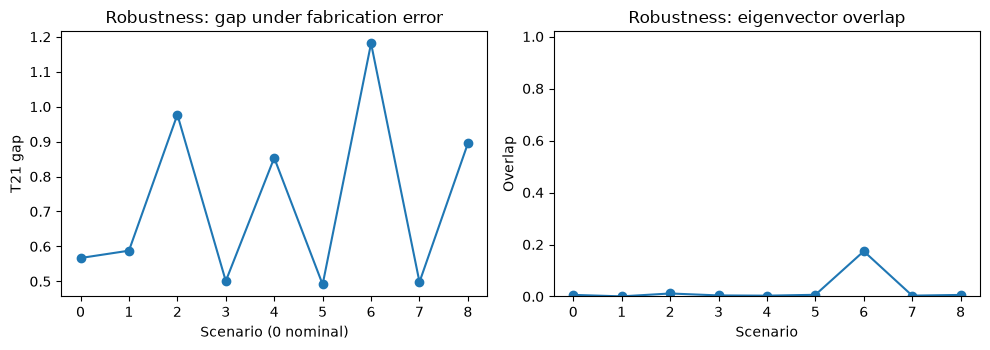

In [36]:
try:
    spread=inverse.FabricationSpread(**checkpoint_meta.get('spread',{}))
except TypeError:
    spread=inverse.FabricationSpread()
print('Fabrication uncertainty (µm):',spread)
print('Penalties:',{k:float(v.detach().cpu()) for k,v in terms.items()})
print('Hard-mask checks:',hard_mask_checks(hard,rules))
heldout=[]
if RUN_FABRICATION_SWEEP:
    setting=RCWASettings(order=5,raster=224,device=DEVICE,precision='complex128')
    heldout=inverse.robust_report(cfg,setting,rules,raw,spread,count=8,seed=8107,hard=True)
    print('scenario  T21 gap     overlap   T12 gap     overlap   unitarity')
    for v in heldout:
        print(f'{v["scenario"]:>4}     {v["T21_gap"]:.3e}   {v["T21_overlap"]:.5f}'
              f'     {v["T12_gap"]:.3e}   {v["T12_overlap"]:.5f}   '
              f'{v["full_S_unitarity"]:.3e}')
    fig,axs=plt.subplots(1,2,figsize=(10,3.6))
    axs[0].plot([v['scenario'] for v in heldout],[v['T21_gap'] for v in heldout],'o-')
    axs[0].set(title='Robustness: gap under fabrication error',xlabel='Scenario (0 nominal)',ylabel='T21 gap')
    axs[1].plot([v['scenario'] for v in heldout],[v['T21_overlap'] for v in heldout],'o-')
    axs[1].set(title='Robustness: eigenvector overlap',xlabel='Scenario',ylabel='Overlap',ylim=(0,1.02))
    fig.tight_layout();plt.show()

## 12. Optional eigenpolarization evolution under rigid in-plane rotation

The entire contour is rigidly rotated by adding a common angle to its ellipse/local Fourier frame. The Jones eigenstate is tracked by vector overlap, and the Pancharatnam phase is a **kinematic closed-path phase**, not automatically an external optical geometric phase. This study requires extra RCWA solves and is disabled by default.

In [37]:
if RUN_ROTATION_TRANSPORT:
    degrees=np.linspace(0.,360.,72)
    paths=[]
    rot_setting=RCWASettings(order=9,raster=192,device=DEVICE,precision='complex128')
    for angle in degrees:
        with torch.no_grad():
            prm=ContourDesign(rules,raw,device=DEVICE,dtype=real_dtype(rot_setting)).values()
            phi=np.deg2rad(angle)
            if MODEL=='ellipse':
                prm['orientation']=prm['orientation']+phi
            else:
                # Fourier coefficient rotation implements r(theta-phi).
                modes=torch.arange(1,rules.harmonics+1,device=DEVICE,dtype=prm['a'].dtype)
                a,b=prm['a'],prm['b']
                prm['a']=a*torch.cos(modes*phi)-b*torch.sin(modes*phi)
                prm['b']=a*torch.sin(modes*phi)+b*torch.cos(modes*phi)
            paths.append(solve_contour_torch(cfg,rot_setting,prm,rules,hard=True,
                          ports=ports).detach().cpu().numpy())
    jones_path,gaps=eigenstate_path(paths)
    print('Min eigenvalue gap:',np.min(gaps))
    print('Geodesically closed Pancharatnam phase (deg):',
          np.rad2deg(pancharatnam_phase(jones_path)))
    fig=plot_path(jones_path);plt.show()
else:
    print('Rotation transport disabled; no extra solves.')

Rotation transport disabled; no extra solves.


## 13. Export and validation summary

Exports a contour SVG and optional GDS mask, plus complete scattering/diagnostics. **No candidate is called a confirmed EP** solely because it passes a finite-tolerance screen. Require stable complex S, eigenvector coalescence, non-scalar Jordan structure, and an appropriate parameter-loop branch-exchange test.

In [38]:
svg=geom.save_contour_svg(OUT/'fourier_contour_mask.svg',points,cfg.period)
if RUN_EXPORT_GDS:
    geom.save_contour_gds(OUT/'fourier_contour_mask.gds',points,cfg.period)
final_S=rc_series[-1]['S'] if rc_series else S_char
np.savez_compressed(OUT/'fourier_contour_validated.npz',
    S=final_S,S_initial=S_char,S_flat=S_base,contour_xy_um=points,
    raw_params=nominal_raw,monitor_z_um=np.asarray(ports),
    orders=np.array([r['order'] for r in rc_series]),
    S_by_order=np.asarray([r['S'] for r in rc_series]).reshape(-1,4,4),
    model=MODEL)
print('Contour SVG:',svg)
print('Completed full-S diagnostics:',metrics(final_S))
print('Near-EP SCREEN (not a proof):',screen_candidate(ep_diagnostics(final_S)))
print('Output:',OUT.resolve())
print('No multilayer or finite-array boundaries are modeled in this notebook.')

Contour SVG: results/fourier_contour_validation/fourier_contour_mask.svg
Completed full-S diagnostics: {'reciprocity_max': 9.261838356760116e-13, 'unitarity_max': 4.664109404569193e-13, 'passivity_lambda_max': 1.000000000000578, 'worst_power_error': 2.569056078982612e-13}
Near-EP SCREEN (not a proof): (False, ['T21: eigenvalue gap too large', 'T21: eigenvectors not coalesced', 'T21: not near rank-one', 'T12: eigenvalue gap too large', 'T12: eigenvectors not coalesced', 'T12: not near rank-one'])
Output: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/results/fourier_contour_validation
No multilayer or finite-array boundaries are modeled in this notebook.


## 14 · **NEW:** Exact saved rotating-stack characterization

Read the optimizer's transport configuration from the checkpoint; do not manually reconstruct a different height or medium. Compare the original isolated contour with the full, direct-contact multilayer Maxwell solve for $N=4,6,8,12,20$ at **fixed total H**. Check the forward/reverse and no-rotation controls, order convergence, non-scalar strength $A(T)$, eigenvalue gap, overlap $\eta$, and reflected/transmitted power. The saved optimization loss is evaluated from the complete stack, not the old isolated single-fin `rc` result.

Full stack N= 4 dir=+1: eta=0.1324 A=0.0660 gap=0.0917 T=0.8513
Full stack N= 4 dir=-1: eta=0.0194 A=0.0798 gap=0.1128 T=0.8477
Full stack N= 4 dir=+0: eta=0.0111 A=0.3918 gap=0.5540 T=0.9353
Full stack N= 6 dir=+1: eta=0.6321 A=0.1636 gap=0.1515 T=0.8234
Full stack N= 6 dir=-1: eta=0.4481 A=0.1821 gap=0.2101 T=0.8373
Full stack N= 6 dir=+0: eta=0.0111 A=0.3918 gap=0.5540 T=0.9353
Full stack N= 8 dir=+1: eta=0.5862 A=0.1764 gap=0.1743 T=0.7876
Full stack N= 8 dir=-1: eta=0.6128 A=0.1804 gap=0.1719 T=0.8071
Full stack N= 8 dir=+0: eta=0.0111 A=0.3918 gap=0.5540 T=0.9353
Full stack N=12 dir=+1: eta=0.5599 A=0.1703 gap=0.1741 T=0.7743
Full stack N=12 dir=-1: eta=0.7520 A=0.1667 gap=0.1242 T=0.7978
Full stack N=12 dir=+0: eta=0.0111 A=0.3918 gap=0.5540 T=0.9353
Full stack N=20 dir=+1: eta=0.4832 A=0.1539 gap=0.1716 T=0.7819
Full stack N=20 dir=-1: eta=0.5983 A=0.1478 gap=0.1437 T=0.7998
Full stack N=20 dir=+0: eta=0.0111 A=0.3918 gap=0.5540 T=0.9353


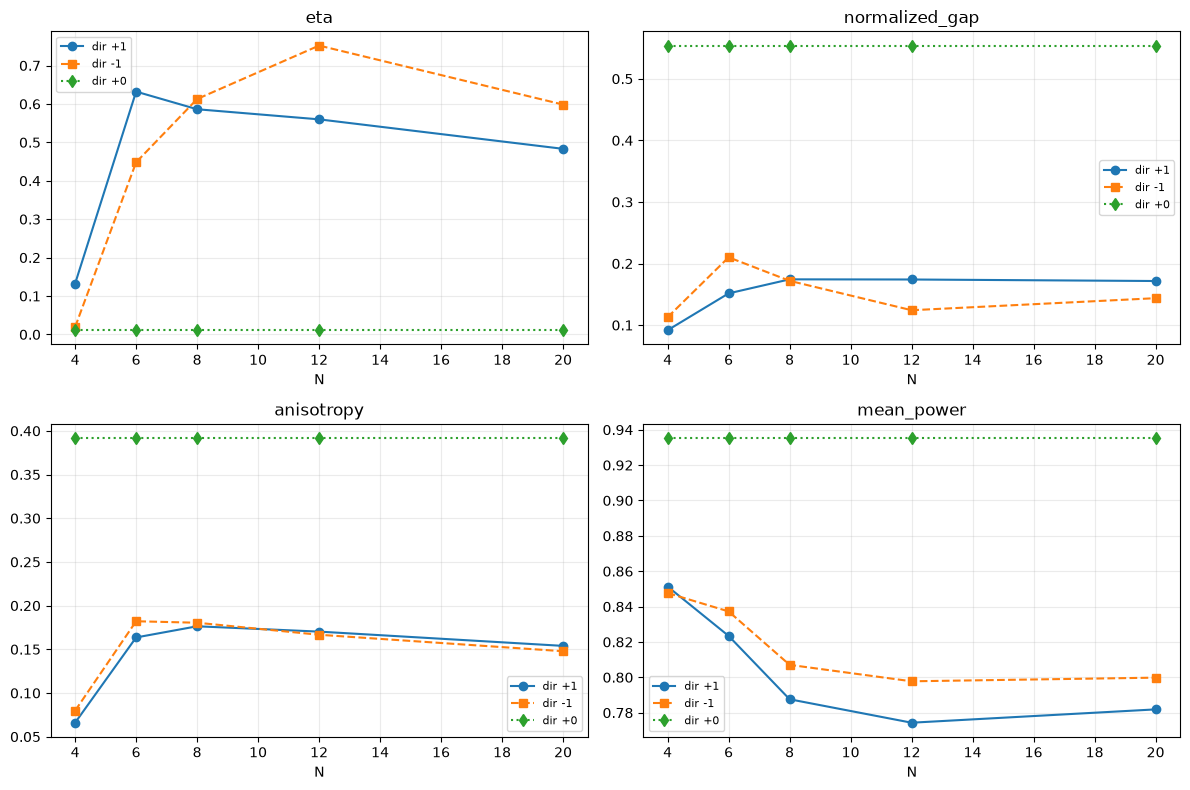

In [39]:
from engine_transport_design import TransportSetup,solve_rotating_stack_torch,solve_embedded_slice_torch
from engine_multilayer_characterization import jones_metrics_numpy

transport_cfg=checkpoint_meta.get('transport')
if not transport_cfg:
    print('No transport metadata: old single-layer checkpoint; run the revised optimizer.')
else:
    setup_dict=transport_cfg['setup']
    H_transport=float(transport_cfg['total_height_um'])
    N_transport=tuple(transport_cfg.get('check_N',(4,6,8,12,20)))
    train_N=int(transport_cfg['train_N'])
    sweep=[]
    test_setting=RCWASettings(order=max(convergence_orders),raster=max(convergence_raster,256),
                     device=DEVICE,precision='complex128')
    with torch.no_grad():
        q=ContourDesign(rules,raw,device=DEVICE,dtype=real_dtype(test_setting)).values()
        for N in N_transport:
            for d in (+1,-1,0):
                setup=TransportSetup(**{**setup_dict,'layers':N,'rotation_sign':d})
                S=solve_rotating_stack_torch(cfg,test_setting,q,rules,
                                            setup=setup,hard=True).detach().cpu().numpy()
                m=jones_metrics_numpy(S[2:4,:2])
                sweep.append(dict(N=N,direction=d,S=S,**m))
                print(f'Full stack N={N:2} dir={d:+d}: eta={m["eta"]:.4f} '
                      f'A={m["anisotropy"]:.4f} gap={m["normalized_gap"]:.4f} '
                      f'T={m["mean_power"]:.4f}')
    fig,axs=plt.subplots(2,2,figsize=(12,8))
    for d,style in [(+1,'o-'),(-1,'s--'),(0,'d:')]:
        x=[v for v in sweep if v['direction']==d]
        for ax,key in zip(axs.flat,('eta','normalized_gap','anisotropy','mean_power')):
            ax.plot([v['N'] for v in x],[v[key] for v in x],style,label=f'dir {d:+d}')
            ax.set(title=key,xlabel='N');ax.grid(alpha=.25)
    for ax in axs.flat:ax.legend(fontsize=8)
    plt.tight_layout();plt.show()
    np.savez_compressed(OUT/'validated_full_stacks.npz',
         N=np.array([v['N'] for v in sweep]),
         direction=np.array([v['direction'] for v in sweep]),
         S=np.array([v['S'] for v in sweep]),H=H_transport)

## 15 · **NEW:** Equal-ambient thin-slice test versus whole-stack response

This experiment deliberately changes the electromagnetic problem to an equal-ambient isolated slice of height $H/N$, while holding its contour fixed. It can expose spurious nonorthogonality caused by external interfaces. **It is not an extraction of the local $K(z)$**; the two-way transfer-generator analysis and the Wilson control are performed in the multilayer notebook.

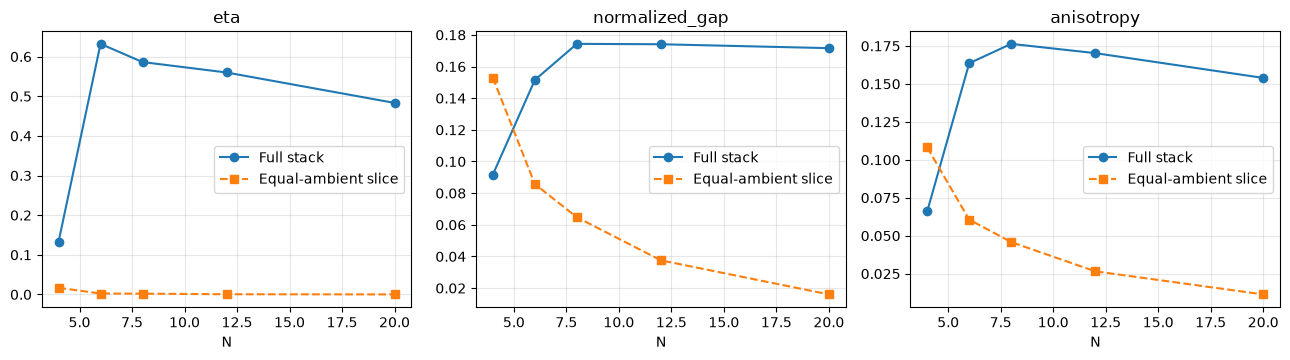

In [40]:
if transport_cfg:
    equal_ambient=[]
    with torch.no_grad():
        for N in N_transport:
            S_slice=solve_embedded_slice_torch(cfg,test_setting,q,rules,
                N=N,background_index=setup_dict['background_index'],hard=True
            ).detach().cpu().numpy()
            m=jones_metrics_numpy(S_slice[2:4,:2])
            equal_ambient.append(dict(N=N,S=S_slice,**m))
    fig,axs=plt.subplots(1,3,figsize=(13,3.7))
    for ax,key in zip(axs,('eta','normalized_gap','anisotropy')):
        stacked=[v for v in sweep if v['direction']==+1]
        ax.plot(N_transport,[v[key] for v in stacked],'o-',label='Full stack')
        ax.plot(N_transport,[v[key] for v in equal_ambient],'s--',label='Equal-ambient slice')
        ax.set(title=key,xlabel='N');ax.legend();ax.grid(alpha=.3)
    plt.tight_layout();plt.show()
    np.savez_compressed(OUT/'validated_embedded_slices.npz',
        N=np.array(N_transport),S=np.array([v['S'] for v in equal_ambient]))